# Практическая работа 6. Langfuse: трейсинг

Выполнены задания:

1. Базовое подключение Langfuse и трейсинг запросов.
4. Эксперименты с параметрами модели и их трейсинг.

Используется локальная версия Langfuse (Docker) и небольшая модель SmolLM2-135M-Instruct, которая запускается через `llama-cpp-python`. Модель понимает в основном английский язык, поэтому запросы к ней написаны на английском.

Каждый запрос к модели записывается в Langfuse как отдельный вызов (generation) с промптом, ответом, моделью, параметрами и числом токенов. Время генерации Langfuse считает сам по началу и концу вызова.

In [1]:
# pip install langfuse llama-cpp-python llm-smollm2 pandas matplotlib

## Подключение

Адрес и ключи берутся из проекта Langfuse (запуск описан в README). Если переменные окружения не заданы, используются значения по умолчанию.

In [2]:
import os, time, json, importlib.util, random, difflib, statistics
import pandas as pd
import matplotlib.pyplot as plt
from llama_cpp import Llama
from langfuse import Langfuse, propagate_attributes

langfuse = Langfuse(
    public_key=os.getenv("LANGFUSE_PUBLIC_KEY", "pk-lf-local"),
    secret_key=os.getenv("LANGFUSE_SECRET_KEY", "sk-lf-local"),
    host=os.getenv("LANGFUSE_HOST", "http://localhost:3000"),
)
print("Подключение к Langfuse:", langfuse.auth_check())

Подключение к Langfuse: True


In [3]:
# файл модели устанавливается вместе с пакетом llm-smollm2
MODEL_NAME = "SmolLM2-135M-Instruct"
MODEL_PATH = os.path.join(importlib.util.find_spec("llm_smollm2").submodule_search_locations[0],
                          "SmolLM2-135M-Instruct.Q4_1.gguf")
llm = Llama(MODEL_PATH, n_ctx=2048, verbose=False)

### Функция с трейсингом

`ask` вызывает модель и записывает вызов в Langfuse. В трейс попадают:
- `input` и `output`: промпт и ответ модели;
- `model` и `model_parameters`: модель и параметры генерации;
- `usage_details`: число токенов в промпте и в ответе;
- `user_id`, `session_id`, теги и `metadata`.

In [4]:
BASE = {"temperature": 0.7, "top_p": 0.95, "max_tokens": 150}   # базовые параметры
SYSTEM = "You are a helpful assistant. Answer briefly."

def ask(question, system=SYSTEM, params=None, name="chat", user_id="user-1",
        session_id="session-1", tags=None, metadata=None):
    p = {**BASE, **(params or {})}
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    with propagate_attributes(user_id=user_id, session_id=session_id, tags=tags or [],
                              metadata={k: str(v) for k, v in (metadata or {}).items()}):
        with langfuse.start_as_current_observation(
                as_type="generation", name=name, model=MODEL_NAME,
                input=messages, model_parameters=p) as gen:
            r = llm.create_chat_completion(messages=messages, **p)
            answer = r["choices"][0]["message"]["content"]
            gen.update(output=answer,
                       usage_details={"input": r["usage"]["prompt_tokens"],
                                      "output": r["usage"]["completion_tokens"]})
    return answer

print(ask("What is a vector database?", tags=["test"]))

A vector database is a data storage system that uses vector-based data types, such as vectors and tensors, to store and manipulate complex data structures. It provides a flexible and composable data model that allows for the creation of complex data structures in a single API. This makes it suitable for various applications, including data science, machine learning, and artificial intelligence.

The concept of vector data was first introduced by Alex Chen and Sergey Brin in 2005, and has since been adopted in various applications such as natural language processing, deep learning, and data science.


## Задание 1. Базовое подключение и трейсинг

### 1.1. 10 тестовых запросов
Запросы идут с тегами `test` и `baseline`, одним `session_id` и двумя пользователями (`user_id`).

In [5]:
questions = [
    "What is a vector database?",
    "Explain what RAG is in one sentence.",
    "Why is the sky blue?",
    "What is the capital of France?",
    "Give three tips for learning Python.",
    "What is the difference between a list and a tuple in Python?",
    "How does a search engine find documents?",
    "What is machine learning?",
    "Name two benefits of unit tests.",
    "What does an API do?",
]

RUN = time.strftime("%Y%m%d-%H%M%S")   # чтобы повторный запуск не смешивался с прошлым
SESSION_1 = f"hw6-task1-{RUN}"
for i, q in enumerate(questions):
    user = "user-1" if i % 2 == 0 else "user-2"
    a = ask(q, name="task1-chat", user_id=user, session_id=SESSION_1, tags=["test", "baseline"])
    print(f"{i+1}. {q}\n   {a[:120]!r}")
langfuse.flush()

1. What is a vector database?
   'A vector database is a data storage system that supports multiple types of data, including vectors (vectors), which are '
2. Explain what RAG is in one sentence.
   'RAG stands for Reduced Analogy Generator, which is a statistical model that helps reduce the complexity of data by ident'


3. Why is the sky blue?
   'The sky is blue because of a process that takes place when light encounters molecules in the air. When light passes from'


4. What is the capital of France?
   'La femme au France, l\'Amérique, la Françonie... (French: "The woman in France, the Americas, Africa...")\n\nThis is a clas'


5. Give three tips for learning Python.
   "1. **Use Python as a Spell-Checker**: Python's syntax and syntax can be easily understood and even learned by those with"


6. What is the difference between a list and a tuple in Python?
   'In Python, a list and a tuple are two different data structures.\n\nA list is a collection of objects. It is a mutable dat'


7. How does a search engine find documents?
   'A search engine uses various methods to find documents, including crawling, indexing, and sorting. Crawling involves the'


8. What is machine learning?
   'Machine learning is a branch of artificial intelligence (AI) that focuses on developing algorithms and models that can l'


9. Name two benefits of unit tests.
   '1. 1.Unit tests reduce the time and effort spent by developers to write unit tests. This is beneficial for both develope'


10. What does an API do?
   'An API (Application Programming Interconnection) is a communication protocol that allows businesses and users to share d'


### 1.2. Данные трейсов из Langfuse
Записи читаются обратно через API Langfuse. Передача данных на сервер идет с небольшой задержкой, поэтому функция ждет, пока появятся все записи.

In [6]:
def load_observations(session_id, expected, tries=30):
    langfuse.flush()
    for _ in range(tries):
        rows, cursor = [], None
        while True:
            r = langfuse.api.observations.get_many(session_id=session_id, limit=100, cursor=cursor,
                                                   fields="core,basic,usage,io,time,model,metadata")
            rows += r.data
            cursor = r.meta.cursor if getattr(r, "meta", None) else None
            if not cursor:
                break
        if len(rows) >= expected:
            break
        time.sleep(3)
    return rows

obs = load_observations(SESSION_1, expected=len(questions))
df1 = pd.DataFrame([{
    "name": o.name, "user": o.user_id, "model": o.model,
    "latency_s": o.latency,
    "tokens_in": (o.usage_details or {}).get("input"),
    "tokens_out": (o.usage_details or {}).get("output"),
    "tokens_total": (o.usage_details or {}).get("total"),
    "start": o.start_time,
} for o in obs]).sort_values("start").reset_index(drop=True)
df1.drop(columns="start")

,name,user,model,latency_s,tokens_in,tokens_out,tokens_total
0,task1-chat,user-1,SmolLM2-135M-Instruct,0.824,29,150,179
1,task1-chat,user-2,SmolLM2-135M-Instruct,0.171,32,30,62
2,task1-chat,user-1,SmolLM2-135M-Instruct,0.536,29,106,135
3,task1-chat,user-2,SmolLM2-135M-Instruct,0.402,30,72,102
4,task1-chat,user-1,SmolLM2-135M-Instruct,0.548,30,113,143
5,task1-chat,user-2,SmolLM2-135M-Instruct,0.796,36,150,186
6,task1-chat,user-1,SmolLM2-135M-Instruct,0.743,31,150,181
7,task1-chat,user-2,SmolLM2-135M-Instruct,0.667,28,127,155
8,task1-chat,user-1,SmolLM2-135M-Instruct,0.433,30,78,108
9,task1-chat,user-2,SmolLM2-135M-Instruct,0.819,29,150,179


### 1.3. Анализ: длительность и токены

In [7]:
print(df1[["latency_s", "tokens_in", "tokens_out", "tokens_total"]].describe().round(2))
print()
print("Корреляция числа токенов ответа и времени:",
      round(df1["tokens_out"].corr(df1["latency_s"]), 2))
print("Среднее время на один токен ответа, мс:",
      round((df1["latency_s"] / df1["tokens_out"]).mean() * 1000, 1))
print()
print(df1.groupby("user")[["latency_s", "tokens_out"]].mean().round(2))

       latency_s  tokens_in  tokens_out  tokens_total
count      10.00      10.00       10.00         10.00
mean        0.59      30.40      112.60        143.00
std         0.22       2.27       41.52         41.58
min         0.17      28.00       30.00         62.00
25%         0.46      29.00       85.00        114.75
50%         0.61      30.00      120.00        149.00
75%         0.78      30.75      150.00        179.00
max         0.82      36.00      150.00        186.00

Корреляция числа токенов ответа и времени: 0.99
Среднее время на один токен ответа, мс: 5.3

        latency_s  tokens_out
user                         
user-1       0.62       119.4
user-2       0.57       105.8


### 1.4. Структура вызова
Для проверки структуры вызова записан трейс с вложенными шагами: общий шаг `rag-pipeline`, внутри него поиск контекста (`retrieve`) и генерация ответа (`generation`). В интерфейсе Langfuse такой трейс отображается деревом, видно время каждого шага.

In [8]:
DOCS = {
    "python": "Python is a programming language. Lists are mutable, tuples are not.",
    "france": "Paris is the capital of France. It is located on the Seine river.",
}

def pipeline(question, session_id):
    with propagate_attributes(user_id="user-1", session_id=session_id, tags=["test", "pipeline"]):
        with langfuse.start_as_current_observation(as_type="span", name="rag-pipeline", input=question) as root:
            with langfuse.start_as_current_observation(as_type="span", name="retrieve", input=question) as s:
                time.sleep(0.05)
                key = "france" if "France" in question else "python"
                context = DOCS[key]
                s.update(output=context)
            answer = ask(f"Context: {context}\nQuestion: {question}", name="generation",
                         session_id=session_id, tags=["test", "pipeline"])
            root.update(output=answer)
    return answer

print(pipeline("What is the capital of France?", SESSION_1 + "-structure"))
print(pipeline("Are tuples mutable?", SESSION_1 + "-structure"))
langfuse.flush()

La femme d'Amsterdam, Paris, est le grand payseur de la France.


In Python, tuples are not mutable. Tuples are immutable data structures that cannot be modified after creation. They are defined using the `tuple` keyword and are immutable.

When you use mutable data structures in Python, they can be modified after their creation, which can introduce new bugs. Tuples, on the other hand, are immutable and can only be modified at runtime.

Here's an example:
```python
my_tuple = (1, "hello", 3.14, "python")
my_tuple[0] = 10
print(my_tuple)  # Output: (1, "hello", 3.14, "python")
```
In


In [9]:
tree = load_observations(SESSION_1 + "-structure", expected=6)
by_trace = {}
for o in tree:
    by_trace.setdefault(o.trace_id, []).append(o)
for obs_list in sorted(by_trace.values(), key=lambda l: min(o.start_time for o in l)):
    for o in sorted(obs_list, key=lambda o: (o.parent_observation_id is not None, o.start_time)):
        indent = "" if o.parent_observation_id is None else "  "
        print(f"{indent}{o.type:<10} {o.name:<14} {o.latency:.2f} s")
    print()

SPAN       rag-pipeline   0.24 s
  SPAN       retrieve       0.05 s
  GENERATION generation     0.18 s

SPAN       rag-pipeline   1.10 s
  SPAN       retrieve       0.05 s
  GENERATION generation     1.05 s



### Вывод по заданию 1
Трейсинг в Langfuse записывает каждый вызов модели вместе с промптом, ответом, параметрами, числом токенов и временем без ручных замеров. Теги, `user_id` и `session_id` позволяют отбирать вызовы по группам (например, только `baseline` или только один пользователь). У вложенных шагов видно, сколько времени занимает каждый из них. Время ответа почти прямо зависит от числа токенов в ответе, поэтому ограничение `max_tokens` напрямую сокращает время.

## Задание 4. Эксперименты с параметрами модели

### 4.1. План эксперимента
Базовые параметры: `temperature=0.7`, `top_p=0.95`, `max_tokens=150`. Проверяются:
- `temperature`: 0.2, 0.7, 1.0;
- `max_tokens`: 40 и 150;
- два системных промпта: короткий ответ и подробный ответ.

Всего 12 вариантов, каждый запускается 5 раз на одном и том же вопросе. Все параметры записываются в `metadata` и в теги трейса.

In [10]:
QUESTION = "Describe a good way to start learning programming."
SYSTEMS = {
    "short": "You are a helpful assistant. Answer in one or two sentences.",
    "detailed": "You are a helpful assistant. Give a detailed answer with several steps.",
}
TEMPS = [0.2, 0.7, 1.0]
MAX_TOKENS = [40, 150]
REPEATS = 5
SESSION_4 = f"hw6-task4-{RUN}"

results = []
for sys_name, sys_text in SYSTEMS.items():
    for t in TEMPS:
        for mt in MAX_TOKENS:
            for rep in range(REPEATS):
                params = {"temperature": t, "max_tokens": mt}
                meta = {"temperature": t, "top_p": BASE["top_p"], "max_tokens": mt,
                        "system_prompt": sys_name, "repeat": rep}
                tags = ["experiment", f"temp-{t}", f"max-{mt}", f"system-{sys_name}"]
                ans = ask(QUESTION, system=sys_text, params=params, name="task4-experiment",
                          session_id=SESSION_4, tags=tags, metadata=meta)
                results.append({"temperature": t, "max_tokens": mt, "system": sys_name,
                                "repeat": rep, "answer": ans})
langfuse.flush()
print("Запросов выполнено:", len(results))

Запросов выполнено: 60


### 4.2. Данные из Langfuse
Время и токены берутся из трейсов Langfuse. Вызов связывается с параметрами через `metadata`.

In [11]:
obs4 = load_observations(SESSION_4, expected=len(results))
rows = []
for o in obs4:
    m = o.metadata or {}
    rows.append({
        "temperature": float(m.get("temperature")), "max_tokens": int(m.get("max_tokens")),
        "system": m.get("system_prompt"), "repeat": int(m.get("repeat")),
        "latency_s": o.latency, "tokens_out": (o.usage_details or {}).get("output"),
        "output": o.output,
    })
df4 = pd.DataFrame(rows).sort_values(["system", "temperature", "max_tokens", "repeat"]).reset_index(drop=True)
print(len(df4), "записей получено из Langfuse")
df4.head()

60 записей получено из Langfuse


,temperature,max_tokens,system,repeat,latency_s,tokens_out,output
0,0.2,40,detailed,0,0.256,40,"To start learning programming, it's essential ..."
1,0.2,40,detailed,1,0.190,40,"To start learning programming, it's essential ..."
2,0.2,40,detailed,2,0.265,40,"To start learning programming, it's essential ..."
3,0.2,40,detailed,3,0.222,40,"To start learning programming, it's essential ..."
4,0.2,40,detailed,4,0.204,40,"To start learning programming, it's essential ..."


### 4.3. Метрики
- **Время генерации**: `latency_s` из Langfuse.
- **Длина ответа**: число слов.
- **Вариативность**: для 5 ответов одного варианта считается, насколько они отличаются друг от друга. Берется `1 - сходство` (через `difflib`) для каждой пары ответов, затем среднее. 0 означает одинаковые ответы, чем ближе к 1, тем разнообразнее ответы.

In [12]:
def variability(texts):
    pairs = [1 - difflib.SequenceMatcher(None, a, b).ratio()
             for i, a in enumerate(texts) for b in texts[i + 1:]]
    return sum(pairs) / len(pairs)

df4["words"] = df4["output"].str.split().str.len()
keys = ["system", "temperature", "max_tokens"]
summary = df4.groupby(keys).agg(
    latency_mean=("latency_s", "mean"), latency_std=("latency_s", "std"),
    words_mean=("words", "mean"), tokens_mean=("tokens_out", "mean"),
).round(2)
summary["variability"] = df4.groupby(keys)["output"].apply(lambda s: variability(list(s))).round(3)
summary.reset_index()

,system,temperature,max_tokens,latency_mean,latency_std,words_mean,tokens_mean,variability
0,detailed,0.2,40,0.23,0.03,33.0,40.0,0.592
1,detailed,0.2,150,0.81,0.04,115.2,150.0,0.855
2,detailed,0.7,40,0.21,0.01,32.4,40.0,0.819
3,detailed,0.7,150,0.80,0.06,111.6,150.0,0.951
4,detailed,1.0,40,0.21,0.02,30.4,40.0,0.727
5,detailed,1.0,150,0.88,0.03,114.4,150.0,0.954
6,short,0.2,40,0.23,0.03,31.8,40.0,0.600
7,short,0.2,150,0.78,0.07,115.8,150.0,0.840
8,short,0.7,40,0.24,0.03,34.0,40.0,0.897
9,short,0.7,150,0.79,0.16,111.8,136.0,0.941


### 4.4. Распределение времени запросов

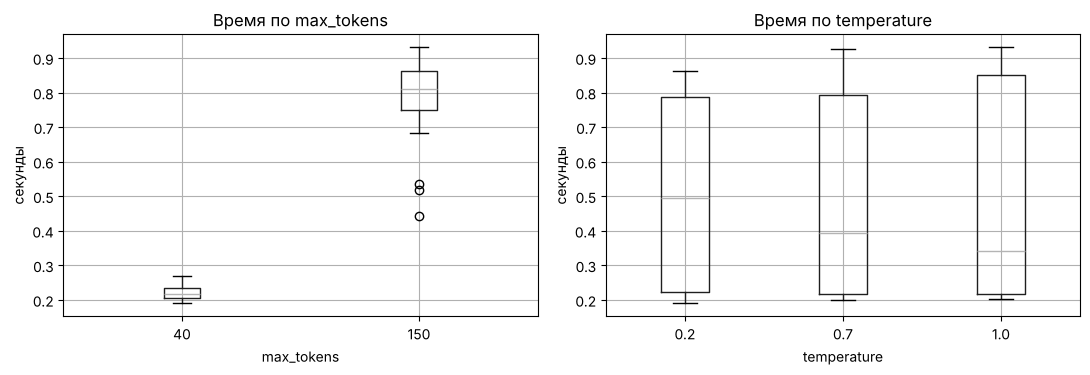

count    60.00
mean      0.50
std       0.30
min       0.19
25%       0.22
50%       0.36
75%       0.81
max       0.93
Name: latency_s, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df4.boxplot(column="latency_s", by="max_tokens", ax=axes[0])
axes[0].set_title("Время по max_tokens"); axes[0].set_xlabel("max_tokens"); axes[0].set_ylabel("секунды")
df4.boxplot(column="latency_s", by="temperature", ax=axes[1])
axes[1].set_title("Время по temperature"); axes[1].set_xlabel("temperature"); axes[1].set_ylabel("секунды")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(df4["latency_s"].describe().round(2))

### 4.5. Лучшие параметры

In [14]:
s = summary.reset_index()
stable = s.sort_values(["variability", "latency_mean"]).iloc[0]
creative = s.sort_values("variability", ascending=False).iloc[0]
fastest = s.sort_values("latency_mean").iloc[0]

def show(title, r):
    print(f"{title}: system={r['system']}, temperature={r['temperature']}, max_tokens={int(r['max_tokens'])} "
          f"(вариативность {r['variability']}, время {r['latency_mean']} с, слов {r['words_mean']})")

show("Самый стабильный ответ", stable)
show("Самый креативный ответ", creative)
show("Минимальное время", fastest)

print()
print("Средняя вариативность по temperature:")
print(s.groupby("temperature")["variability"].mean().round(3))
print("Среднее время по max_tokens:")
print(s.groupby("max_tokens")["latency_mean"].mean().round(2))

Самый стабильный ответ: system=detailed, temperature=0.2, max_tokens=40 (вариативность 0.592, время 0.23 с, слов 33.0)
Самый креативный ответ: system=short, temperature=1.0, max_tokens=150 (вариативность 0.954, время 0.66 с, слов 91.8)
Минимальное время: system=detailed, temperature=0.7, max_tokens=40 (вариативность 0.819, время 0.21 с, слов 32.4)

Средняя вариативность по temperature:
temperature
0.2    0.722
0.7    0.902
1.0    0.830
Name: variability, dtype: float64
Среднее время по max_tokens:
max_tokens
40     0.22
150    0.79
Name: latency_mean, dtype: float64


Примеры ответов при разной температуре (подробный промпт, `max_tokens=150`):

In [15]:
for t in TEMPS:
    row = df4[(df4.system == "detailed") & (df4.temperature == t) & (df4.max_tokens == 150) & (df4.repeat == 0)].iloc[0]
    print(f"temperature={t}:\n{row['output']}\n")

temperature=0.2:
To start learning programming, it's essential to begin with a solid foundation that includes understanding the basics of programming concepts, syntax, and best practices. A good starting point is to start with a beginner's mindset, which involves learning the fundamentals of programming, such as data structures, algorithms, and object-oriented programming.

One of the most effective ways to begin learning programming is by using a beginner's software, such as Scratch, an open-source programming language that allows users to create interactive games and simulations. Scratch allows users to design and develop their own games, which can be used to learn programming concepts and syntax.

Another excellent way to start learning programming is by using a beginner's IDE, such as Visual Studio Code (VS Code

temperature=0.7:
When starting programming, it's essential to pick a language that excels in your skillset, which is often a beginner-friendly language with a vast ecosyst

### Вывод по заданию 4
- **Время генерации** зависит в основном от `max_tokens`: при 40 токенах ответ занимает около 0,2 с, при 150 токенах около 0,8 с. Температура и системный промпт на время почти не влияют, кроме случаев, когда модель сама заканчивает ответ раньше лимита (короткий промпт при `max_tokens=150`).
- **Самый стабильный ответ** получается при `temperature=0.2`: ответы одного варианта похожи друг на друга сильнее, чем при 0,7 и 1,0. Полностью одинаковыми они не становятся: слова выбираются случайно даже при низкой температуре.
- **Самый креативный ответ** дают высокие температуры (0,7 и 1,0) и длинный лимит токенов: ответы сильно отличаются друг от друга. Разница между 0,7 и 1,0 небольшая и меняется от запуска к запуску, так как для каждого варианта сделано только 5 повторов.
- **Минимальное время** дают варианты с `max_tokens=40`, но такой ответ обрывается на середине мысли. Для практического использования нужен баланс между длиной ответа и временем.
- Итог: `temperature` управляет разнообразием ответов, `max_tokens` управляет длиной и временем, системный промпт задает стиль и длину ответа. Все параметры записаны в `metadata` и тегах, поэтому в интерфейсе Langfuse можно отфильтровать вызовы по любому из них.

In [16]:
langfuse.flush()
print("Данные отправлены в Langfuse:", os.getenv("LANGFUSE_HOST", "http://localhost:3000"))

Данные отправлены в Langfuse: http://localhost:3000
